# Tutorial 5: Human tonsil (spatial-ATAC-seq)

**Scientific question.** Can a motif-informed chromatin model summarize broad spatial organization in a human tonsil section?

This example profiles spatial chromatin accessibility in human tonsil using spatial-ATAC-seq (2,488 spots). SEAREG trains on the count matrix, spatial coordinates, and peak–motif annotations. Here, “joint UMAP” means a shared display of spot, peak, and motif embeddings.

**Original study.** [Deng et al., Nature (2022)](https://doi.org/10.1038/s41586-022-05094-1); [GEO GSE171943](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE171943).

Run the cells in order to prepare the data and network, train SEAREG, and analyze the trained model’s final embeddings.


## 1. Environment and configuration

Create the pinned Python 3.10 environment and install the CPU or CUDA stack following the [installation guide](../docs/installation.rst). Open this notebook in that environment. The default inputs are under `data/Tonsil/`; see [input data](../docs/data_access.rst).

Edit `ATAC_PATH`, optional `MOTIF_PATH`, `OUTPUT_DIR`, `DATASET` and `TARGET_K` below for your own data. `DATASET` labels the run; `CONFIG_PATH` remains an independently selected defaults profile. The option dictionaries expose the original filtering, network, training, analysis and execution settings for overrides. Use `MOTIF_OPTIONS["enabled"]=False` for counts-only training, or configure how to read or scan motifs. Paths may be outside the repository.

Select a physical CUDA card with `SEAREG_PHYSICAL_GPU` (default: 0). For CPU training, set `TRAINING_OPTIONS["device"]="cpu"` and `EXECUTION_OPTIONS["physical_gpu"]=None`, with `SEAREG_PHYSICAL_GPU` unset. The detached training job records the effective settings.

Keep `RUN_MODE="train"` to execute the complete workflow. Each execution creates a new run and analyzes its final embeddings. Rerun from this cell after changing configuration.


In [1]:
from pathlib import Path
from dataclasses import asdict
import hashlib
import json
import os
import sys
import time
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "seareg" / "__init__.py").is_file() and (p / "tutorials").is_dir())
sys.path.insert(0, str(ROOT))
import seareg as sr
sys.path.insert(0, str(ROOT / "tutorials"))
from seareg_tutorial_data import prepare_input_file, create_run_directory
from seareg_tutorial_embeddings import load_tutorial_embeddings

# One input interface: the bundled paths and settings below are editable defaults.
# Keep the profile independent of the run label; a new DATASET needs no new profile.
CONFIG_PATH = ROOT / "tutorials" / "configs" / "Tonsil.json"
profile = json.loads(CONFIG_PATH.read_text())
DATASET = "Tonsil"  # A label for this run.
RUN_MODE = "train"  # "train" or "provided"; rerun from this cell after changing inputs.
ATAC_PATH = (CONFIG_PATH.parent / profile["input"]["atac"]).resolve()
MOTIF_PATH = ((CONFIG_PATH.parent / profile["input"]["dna"]).resolve()
              if profile["input"].get("dna") else None)
EMBEDDING_DIR = ROOT / "result" / "Tonsil" / "training" / "embeddings" / "500_epoch"
OUTPUT_DIR = ROOT / "result" / DATASET  # May be any writable directory.
TARGET_K = profile["analysis"]["target_domains"][0]

# Set enabled=False for counts-only training. With source="auto", a missing
# motif matrix uses the Workflow's R scanner after filtering. Select the actual
# assembly (or counts metadata) and species; fasta may name a local reference.
MOTIF_OPTIONS = {
    "enabled": True,
    "source": "auto",  # "auto", "read", or "scan".
    "genome": os.environ.get("SEAREG_REFERENCE_ASSEMBLY", "").strip() or None,
    "fasta": os.environ.get("SEAREG_REFERENCE_FASTA", "").strip() or None,
    "species_names": [name.strip() for name in os.environ.get(
        "SEAREG_MOTIF_SPECIES", "Homo sapiens,Mus musculus").split(",") if name.strip()],
    "rscript": os.environ.get("SEAREG_RSCRIPT", "Rscript"),
    "threads": 1,
    "auto_build_dna": True,
    "download_reference": True,
}
# Override individual values here, keeping each example's original defaults.
FILTERING_OPTIONS = {**profile["filtering"]}
NETWORK_OPTIONS = {**profile["network"]}
TRAINING_OPTIONS = {**profile["training"]}
ANALYSIS_OPTIONS = {**profile["analysis"]}
EXECUTION_OPTIONS = {**(profile["execution"] if RUN_MODE == "train" else {
    "physical_gpu": None, "torch_threads": 1, "torch_interop_threads": 1,
    "blas_threads": 1, "strict_algorithms": True, "tf32": False,
})}

if RUN_MODE not in {"provided", "train"}:
    raise ValueError("RUN_MODE must be provided or train")
training_config = sr.TrainConfig(**TRAINING_OPTIONS)
analysis_config = sr.AnalysisConfig(**{**ANALYSIS_OPTIONS, "target_domains": (TARGET_K,)})
execution = dict(EXECUTION_OPTIONS)
if RUN_MODE == "train" and "SEAREG_PHYSICAL_GPU" in os.environ:
    execution["physical_gpu"] = int(os.environ["SEAREG_PHYSICAL_GPU"])
print("SEAREG:", sr.__version__)
print("Dataset / mode:", DATASET, RUN_MODE)
if RUN_MODE == "train":
    print("Training device / physical GPU:", training_config.device, execution["physical_gpu"])
    print("Epochs / shards:", training_config.epochs, training_config.shards)
else:
    print("Using the selected embeddings; no model training or GPU is required.")


SEAREG: 0.5.0.dev3
Dataset / device / physical GPU: Tonsil cuda:0 1
Epochs / shards: 500 10
Loss backend / strict / TF32: auto False False


## 2. Prepare inputs and reserve a new run

Prepare the selected counts path. Existing files are used directly; a missing path that exactly matches a bundled input can be extracted from its checked gzip archive. A missing custom counts path raises an error.

Prepare any selected optional motif archive as file transport, then configure one `sr.Workflow` with the chosen paths and options. Scientific motif import or scanning happens in step 5, after filtering. Each run uses a unique `OUTPUT_DIR/runs/<mode>_<time>_<id>/` directory, including when `OUTPUT_DIR` is outside the repository.


In [2]:
def file_sha256(path):
    hasher = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            hasher.update(block)
    return hasher.hexdigest()

def display_path(path):
    path = Path(path).expanduser().resolve()
    return str(path.relative_to(ROOT)) if path.is_relative_to(ROOT) else str(path)

# Existing selected files are accepted directly. Only a missing exact bundled
# path can use checked archive extraction; custom paths never select an example.
ATAC_PATH = prepare_input_file(ATAC_PATH, bundle_root=ROOT)
input_hashes = {display_path(ATAC_PATH): file_sha256(ATAC_PATH)}
OUTPUT_DIR = Path(OUTPUT_DIR).expanduser().resolve()
provided_embeddings = None
if RUN_MODE == "provided":
    EMBEDDING_DIR = Path(EMBEDDING_DIR).expanduser().resolve()
    provided_embeddings = load_tutorial_embeddings(EMBEDDING_DIR, counts_path=ATAC_PATH)
elif MOTIF_OPTIONS["enabled"] and MOTIF_PATH is not None and MOTIF_OPTIONS["source"] != "scan":
    MOTIF_PATH = Path(MOTIF_PATH).expanduser().resolve()
    # Transport only: matrix import and scanning occur in step 5, after filtering.
    prepare_input_file(MOTIF_PATH, bundle_root=ROOT, required=False)

# Check chosen counts (and provided exports) before reserving any output.
RUN_DIR = create_run_directory(ROOT, DATASET, RUN_MODE, output=OUTPUT_DIR)
stage_seconds = {}
notebook_started = time.perf_counter()
flow = None
if RUN_MODE == "train":
    inputs = {"atac": str(ATAC_PATH)}
    if MOTIF_OPTIONS["enabled"] and MOTIF_PATH is not None:
        inputs["dna"] = str(Path(MOTIF_PATH).expanduser().resolve())
    motif_options = {key: value for key, value in MOTIF_OPTIONS.items() if value is not None}
    if motif_options.get("fasta"):
        motif_options["fasta"] = str(Path(motif_options["fasta"]).expanduser().resolve())
    if "/" in str(motif_options.get("rscript", "")):
        motif_options["rscript"] = str(Path(motif_options["rscript"]).expanduser().resolve())
    run_profile = {**profile, "schema_version": 2, "dataset_id": DATASET,
                   "input": inputs, "motif": motif_options, "output": str(RUN_DIR),
                   "filtering": FILTERING_OPTIONS, "network": NETWORK_OPTIONS,
                   "training": TRAINING_OPTIONS,
                   "analysis": {**ANALYSIS_OPTIONS, "target_domains": [TARGET_K]},
                   "execution": execution}
    flow = sr.Workflow(run_profile)
    # Capture the actual matrix selected by Workflow, including local auto-discovery.
    selected_motif_path = flow.config["input"].get("dna")
    if selected_motif_path is not None:
        input_hashes[display_path(selected_motif_path)] = file_sha256(selected_motif_path)
print("Run:", display_path(RUN_DIR))
print("Input SHA-256:", input_hashes)


Fresh run: results/Tonsil/github_fresh_20261019T182113Z
Verified input SHA-256: {'data/Tonsil/counts.h5ad': 'f3eb48244bf5c74c83587e5fbbbab5f15e32030241da212f308f0fb33d35f5c6', 'data/Tonsil/motifs.h5': '6de8ede8277b62a139d8e0775e2fdc0b69b5e4adb12ab634810f187dcfd95dd5'}


## 3. Inspect counts and spatial coordinates

Preview a backed matrix slice: rows are spots and columns are genomic peaks. Read spatial coordinates in their native XY orientation.


In [3]:
import anndata as ad
import numpy as np
import pandas as pd

adata = ad.read_h5ad(ATAC_PATH, backed="r")
try:
    print(adata)
    # Select sparse major-axis vectors without materializing the full matrix.
    matrix = adata.X
    if getattr(matrix, "format", None) == "csr":
        block = matrix[np.arange(adata.n_obs) < 5, :5]
    elif getattr(matrix, "format", None) == "csc":
        block = matrix[:5, np.arange(adata.n_vars) < 5]
    else:
        block = matrix[:5, :5]
    values = block.toarray() if hasattr(block, "toarray") else np.asarray(block)
    display(pd.DataFrame(values, index=adata.obs_names[:5], columns=adata.var_names[:5]))
    display(pd.DataFrame(np.asarray(adata.obsm["spatial"])[:5, :2],
                         index=adata.obs_names[:5], columns=["x", "y"]))
finally:
    adata.file.close()
del adata, matrix, block, values


AnnData object with n_obs × n_vars = 2488 × 25362 backed at '/home/disk1/xiemingyu/download/SEAREG/data/Tonsil/counts.h5ad'
    obsm: 'spatial'


,chr1-9956-10287,chr1-180775-181048,chr1-181258-181528,chr1-191245-191490,chr1-629592-630027
AACGTGATAACGTGAT-1,0,0,0,0,0
AACGTGATAAACATCG-1,0,0,0,0,0
AACGTGATATGCCTAA-1,0,0,0,0,0
AACGTGATAGTGGTCA-1,0,0,0,0,0
AACGTGATACCACTGT-1,0,0,0,0,0


,x,y
AACGTGATAACGTGAT-1,1384,-686
AACGTGATAAACATCG-1,1384,-694
AACGTGATATGCCTAA-1,1384,-702
AACGTGATAGTGGTCA-1,1384,-710
AACGTGATACCACTGT-1,1384,-718


## 4. Filter the count matrix

Apply `copy1_frequency_v1` chromosome and peak-frequency filters, then save the retained counts and peak IDs.


In [4]:
if RUN_MODE == "train":
    started = time.perf_counter()
    filtered = flow.filter()
    stage_seconds["filter_counts"] = time.perf_counter() - started
    if filtered.metadata["source"]["sha256"] != input_hashes[display_path(ATAC_PATH)]:
        raise ValueError("Counts changed between validation and filtering")
    print("Filtered shape:", filtered.metadata["shape"])
    print("Retained peaks:", len(filtered.peak_ids))
else:
    print("Skipped in provided mode; analysis uses the supplied embeddings.")


Filtered shape: (2488, 25186)
Retained peaks: 25186


## 5. Prepare peak–motif annotations

Import the selected peak–motif matrix or scan the retained peaks with `flow.prepare_motif()`. Set `MOTIF_OPTIONS["enabled"]=False` for a counts-only model.

For scanning, select the assembly and species in the first cell; optionally provide a local reference FASTA. See [motif annotation](../docs/motif_annotation.rst) for R setup and scanner options.


In [5]:
if RUN_MODE == "train":
    started = time.perf_counter()
    selected_motif = flow.prepare_motif()
    stage_seconds["prepare_motif"] = time.perf_counter() - started
    motif_input = {"enabled": flow.config["motif"]["enabled"],
                   "mode": flow.config["motif"]["mode"],
                   "filtered_peak_axis_hash": filtered.metadata["peak_axis_hash"]}
    if selected_motif is None:
        print("Motifs are disabled; the network will contain spots and peaks.")
    else:
        motif_input.update(selected_edges=display_path(selected_motif.path),
                           artifact_fingerprint=selected_motif.fingerprint)
        matrix_path = flow.config["input"].get("dna")
        if "legacy_annotation" in selected_motif.metadata.get("upstreams", {}):
            annotation_artifact = selected_motif.upstream("legacy_annotation", sr.AnnotationResult)
            matrix_path = annotation_artifact.path / "freq_motif.h5"
            motif_input["scanner_provenance"] = display_path(
                annotation_artifact.path / "scanner.provenance.json")
        if matrix_path is not None:
            motif_digest = file_sha256(matrix_path)
            previous_digest = input_hashes.get(display_path(matrix_path), motif_digest)
            if (motif_digest != previous_digest or
                    selected_motif.metadata["source"]["sha256"] != motif_digest):
                raise ValueError("Motif annotation changed between selection and import")
            input_hashes[display_path(matrix_path)] = motif_digest
            motif_input.update(path=display_path(matrix_path), sha256=motif_digest)
        matrix = selected_motif.load_matrix()
        motif_input["source_shape"] = list(matrix.shape)
        print("Peak × motif matrix:", matrix.shape)
        display(pd.DataFrame(matrix[:5, :5].toarray(),
                             index=selected_motif.peak_ids[:5], columns=selected_motif.motif_ids[:5]))
        del matrix
else:
    print("Skipped in provided mode; analysis uses the selected embeddings.")


Peak × motif matrix: (25186, 849)


,PAX6_MA0069_1,RORA_MA0071_1,RXRA_VDR_MA0074_1,REL_MA0101_1,RELA_MA0107_1
chr1_9956_10287,0.0,0.0,0.0,0.0,0.0
chr1_180775_181048,0.0,0.0,0.0,0.0,0.0
chr1_181258_181528,0.0,0.0,0.0,0.0,0.0
chr1_191245_191490,0.0,0.0,0.0,0.0,0.0
chr1_629592_630027,0.0,0.0,0.0,0.0,0.0


## 6. Build the network

`flow.prepare_network()` builds the network from the filtered counts and selected optional motif artifact. When motifs are enabled, align annotations to the retained peaks, merge duplicate motif columns and remove empty columns. Construct the configured spatial graph and inspect the actual node and edge counts.


In [6]:
if RUN_MODE == "train":
    started = time.perf_counter()
    network = flow.prepare_network()
    stage_seconds["build_network"] = time.perf_counter() - started
    prepared_data = network.load_data()
    node_counts = {"spots": len(prepared_data.spot_ids), "peaks": len(prepared_data.peak_ids),
                   "motifs": len(prepared_data.dna_ids)}
    display(pd.DataFrame([{"entity": key, "nodes": value} for key, value in node_counts.items()]))
    print("Spot–peak / peak–motif edges:", prepared_data.X.nnz,
          prepared_data.dna.nnz if prepared_data.dna is not None else 0)
    graph_report = json.loads((network.path / "graph_report.json").read_text())
    if graph_report["enabled"]:
        display(pd.DataFrame(graph_report["slices"]))
    else:
        print("Spatial graph is disabled for this run.")
    del prepared_data
else:
    print("Skipped in provided mode; analysis uses the supplied embeddings.")


,entity,nodes
0,spots,2488
1,peaks,25186
2,motifs,836


Spot–peak / peak–motif edges: 3606237 400207


,slice,spots,directed_edges
0,sample,2488,111050


## 7. Prepare training inputs

Build the split and sampler inputs from the network. The configured `tr=1.0` uses all observed positive edges for training.


In [7]:
if RUN_MODE == "train":
    started = time.perf_counter()
    training_inputs = flow.prepare_training()
    stage_seconds["prepare_training"] = time.perf_counter() - started
    print("Training-input fingerprint:", training_inputs.fingerprint)
    print("Scientific settings:", {key: getattr(training_config, key) for key in
          ("seed", "epochs", "hidden_dim", "shards", "pn_r", "tr", "spatial_weight", "dna_weight")})
else:
    print("Skipped in provided mode; analysis uses the supplied embeddings.")


Training-input fingerprint: 8771797ae8de808efaf6be1c9f0c1a77bd3c1d6b291e8336ef6a37dd2616098c
Scientific settings: {'seed': 1234, 'epochs': 500, 'hidden_dim': 64, 'shards': 10, 'pn_r': 10, 'tr': 1.0, 'spatial_weight': 0.2, 'dna_weight': 0.1}


## 8. Initialize and train SEAREG

Train a fresh model and optimizer for the configured epochs in an independent tmux job. One progress bar updates in place; the final training statistics and last five epochs are shown below.

Full runtime records and recovery files are saved with the run. See [training and recovery](../docs/workflow.rst).


In [8]:
if RUN_MODE == "train":
    from seareg_tutorial_display import single_line_training_progress
    started = time.perf_counter()
    job = sr.start_training_job(training_inputs, training_config, RUN_DIR / "training",
                                execution=execution, name=DATASET)
    print("Independent training job:", job.path)
    print("Recovery and logs:", job.path / "TRAINING_HANDOFF.md")
    with single_line_training_progress():
        training = job.wait()
    stage_seconds["training_process"] = time.perf_counter() - started
    training_metadata = training.manifest["metadata"]
    print("Final epoch / optimizer updates:", training.final_epoch, training_metadata["optimizer_steps"])
    print("Actual backend steps:", training_metadata["loss_execution"]["backend_step_counts"])
    print("PyTorch peak memory (bytes):", training_metadata["torch_memory"])
    display(pd.read_csv(training.path / "training_history.tsv", sep="\t").tail())
else:
    training = None
    training_metadata = None
    stage_seconds["training_process"] = None
    print("No training was performed. The next cell loads the provided embeddings.")


100%|██████████| 500/500 [02:31<00:00,  3.29it/s]


Final epoch / optimizer updates: 500 5000
Actual backend steps: {'cuda_fused': 5000}
PyTorch peak memory (bytes): {'scope': 'PyTorch allocator since training setup; excludes non-PyTorch allocations', 'peak_allocated_bytes': 2111692800, 'peak_reserved_bytes': 2164260864, 'process_peak_vram_bytes': None, 'process_peak_evidence': 'not_measured_by_allocator_counters'}


,loss,bpr,reg,reg_dna,triplet,epoch,optimizer_steps,nonempty_shards,anchor_pairs,epoch_seconds_excluding_export
495,0.371632,0.268431,103.148532,5.239320,0.0,496,4960,10,0,0.440983
496,0.371408,0.267964,103.391024,5.250744,0.0,497,4970,10,0,0.168236
497,0.371182,0.267497,103.631637,5.262125,0.0,498,4980,10,0,0.166510
498,0.370957,0.267034,103.870464,5.273538,0.0,499,4990,10,0,0.166554
499,0.370734,0.266574,104.107483,5.284976,0.0,500,5000,10,0,0.166648


## 9. Load node embeddings

Load the completed `TrainingRun`’s final propagated spot, peak and optional motif embeddings with `load_tutorial_embeddings`. The following analysis and plotting cells use this `embeddings` object.


In [9]:
embedding_source = training if RUN_MODE == "train" else EMBEDDING_DIR
if RUN_MODE == "train":
    embeddings = load_tutorial_embeddings(embedding_source, counts_path=ATAC_PATH)
else:
    # Step 2 already validated and loaded these exact selected files before reserving a run.
    embeddings = provided_embeddings
EMBEDDING_DIR = Path(embeddings.provenance["export_path"])
entity_frames = {"spot": embeddings.spot, "peak": embeddings.peak, "motif": embeddings.motif}
analysis_node_counts = {"spots": len(embeddings.spot), "peaks": len(embeddings.peak),
                        "motifs": len(embeddings.motif) if embeddings.motif is not None else 0}
display(pd.DataFrame([
    {"entity": entity, "rows": len(frame), "dimensions": frame.shape[1]}
    for entity, frame in entity_frames.items() if frame is not None
]))
display(embeddings.spot.iloc[:5, :5])

if RUN_MODE == "provided":
    node_counts = dict(analysis_node_counts)


,entity,rows,dimensions
0,spot,2488,64
1,peak,25186,64
2,motif,836,64


,latent_0,latent_1,latent_2,latent_3,latent_4
entity_id,,,,,
AACGTGATAACGTGAT-1,0.161677,-1.142534,0.718651,-0.687212,-0.479745
AACGTGATAAACATCG-1,-0.005889,-0.664609,0.478988,-0.950878,-0.039993
AACGTGATATGCCTAA-1,0.348623,-0.138567,0.360023,-0.133680,0.445298
AACGTGATAGTGGTCA-1,0.078800,-0.221794,0.390221,-0.324603,0.034715
AACGTGATACCACTGT-1,0.499312,-0.601832,-0.077932,-0.208626,0.418499


## 10. Identify domains and fit UMAPs

`sr.analyze(embeddings, analysis_config, ...)` analyzes the embedding set loaded in step 9. With the default settings, spatial domains use float64 row-L2 spot embeddings, PCA20, Scanpy with 15 Euclidean neighbors, and exact-K Louvain search for **K=3** (seed 0). Edit `TARGET_K` to change the domain count. Spot UMAP uses this graph.

Joint UMAP row-normalizes each node type in float64, concatenates all spots, peaks and any motifs, and fits direct 2D UMAP with 15 Euclidean neighbors. Both UMAPs use seed 1234 and `min_dist=0.08`.


In [10]:
started = time.perf_counter()
from threadpoolctl import threadpool_limits
with threadpool_limits(limits=execution["blas_threads"]):
    result = sr.analyze(embeddings, analysis_config, RUN_DIR / "analysis", plots=False)
stage_seconds["analysis_process"] = time.perf_counter() - started
domain_result = result.domains(TARGET_K) if analysis_config.domains else None
spot_result = result.spot_embedding() if analysis_config.spot_umap else None
joint_result = result.joint_embedding() if analysis_config.joint else None
if domain_result is not None:
    print("Recomputed spatial domains:", domain_result.target_k)
    print("Final resolution-search step:", domain_result.trace[-1])
    display(domain_result.labels.head())
if joint_result is not None:
    display(joint_result.table.groupby("entity_type").size().rename("nodes"))


Recomputed spatial domains: 3
Final resolution-search step: {'iteration': 2, 'resolution': 0.75, 'observed_k': 3}


,spot_id,slice_id,domain
0,AACGTGATAACGTGAT-1,sample,D1
1,AACGTGATAAACATCG-1,sample,D1
2,AACGTGATATGCCTAA-1,sample,D0
3,AACGTGATAGTGGTCA-1,sample,D0
4,AACGTGATACCACTGT-1,sample,D0


entity_type
motif      836
peak     25186
spot      2488
Name: nodes, dtype: int64

## 11. Visualize spatial domains

Plot the spatial-domain labels computed in step 10 using the established example domain names and colors when its partition matches. The spatial, spot UMAP and joint UMAP plots use the same labels. Plot native XY with increasing y and spot area 20 points².


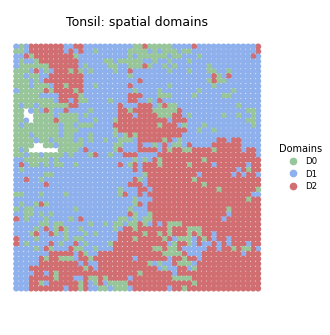

In [11]:
from seareg import plotting
from tutorials.seareg_tutorial_style import tutorial_domain_style
from matplotlib import pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png", bbox_inches=None)
figures = {}
plot_labels, domain_palette = tutorial_domain_style(
    domain_result.labels if domain_result is not None else None, 'Tonsil')
if domain_result is not None:
    figures["spatial_domains"], ax = plotting.spatial_domains(
        domain_result.coordinates, plot_labels, palette=domain_palette,
        title=f"{DATASET}: spatial domains", point_size=20,
    )
    display(figures["spatial_domains"])
    plt.close(figures["spatial_domains"])


## 12. Spot UMAP

Plot the spot UMAP fitted in step 10 using the same spatial-domain names and colors.


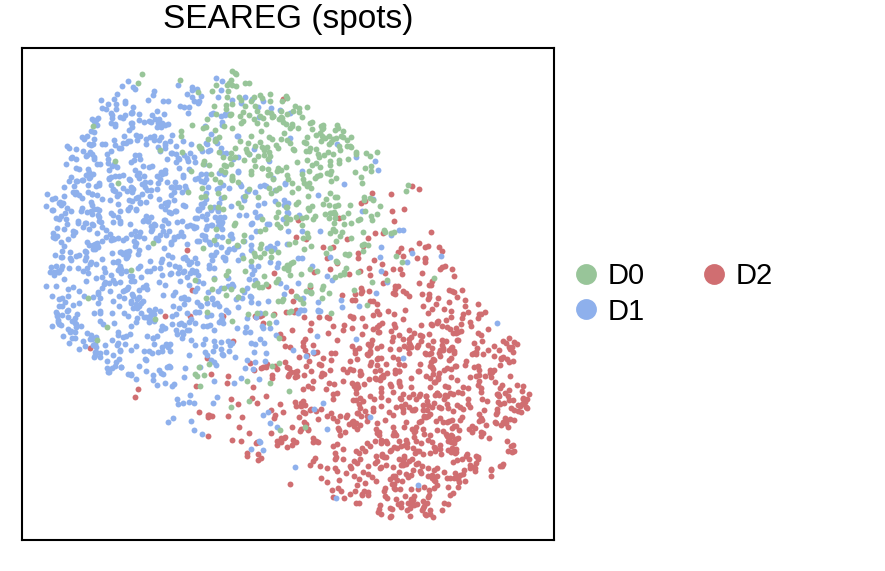

In [12]:
if spot_result is not None:
    figures["spot_umap"], ax = plotting.spot_umap(
        spot_result.table, labels=plot_labels, palette=domain_palette, title="SEAREG (spots)", point_size=2,
    )
    display(figures["spot_umap"], metadata={"image/png": {"width": 950}})
    plt.close(figures["spot_umap"])


## 13. Spot–peak–motif joint UMAP

Plot all learned node types in the shared space: domain-colored circles for spots, gray triangles for peaks and dark squares for motifs when present.


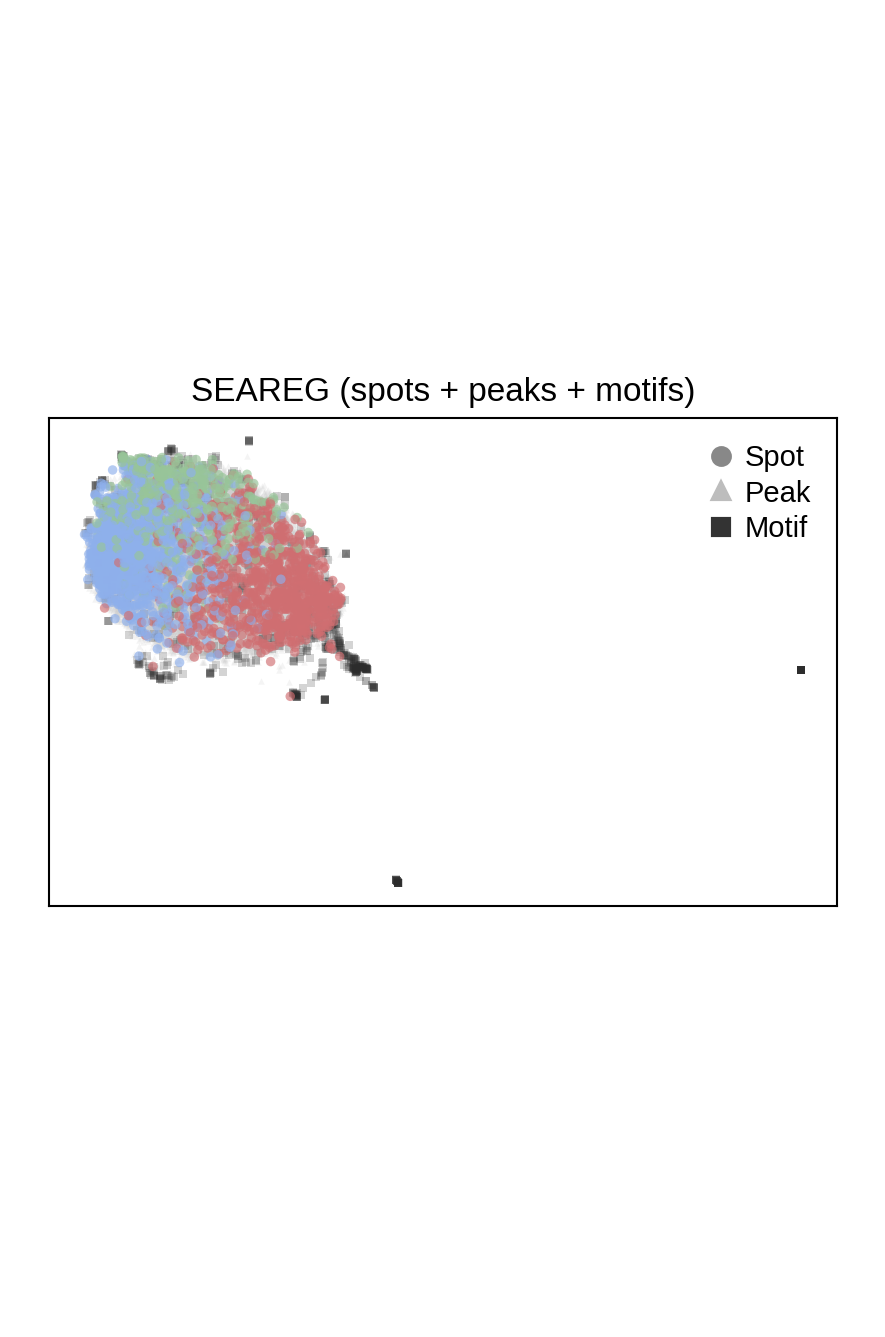

In [13]:
if joint_result is not None:
    figures["joint_umap"], ax = plotting.joint_umap(
        joint_result.table, labels=plot_labels, palette=domain_palette,
        title="SEAREG (spots + peaks + motifs)",
        point_size=5.2, peak_size=2.4, motif_size=4.2,
    )
    display(figures["joint_umap"], metadata={"image/png": {"width": 950}})
    plt.close(figures["joint_umap"])


## 14. Export figures and the execution receipt

Save PNG, editable PDF and SVG figures in `RUN_DIR / "figures"`. The run’s `tutorial_execution.json` records the data, model outputs and analysis configuration.


In [14]:
# Read training metadata for the export receipt.
training_metadata = (json.loads((training.path / "status.json").read_text())
                     if RUN_MODE == "train" else None)
figure_directory = RUN_DIR / "figures"
exports_started = time.perf_counter()
saved_figures = []
for name, fig in figures.items():
    is_embedding = name in {"spot_umap", "joint_umap"}
    paths = plotting.save_figure(fig, figure_directory / name,
                               dpi=300 if is_embedding else 450,
                               bbox_inches=None if is_embedding else "tight")
    saved_figures.extend({"figure": name, "file": path.name} for path in paths)
    plt.close(fig)
package_root = Path(sr.__file__).parent
source_hashes = {str(path.relative_to(package_root)): hashlib.sha256(path.read_bytes()).hexdigest()
                 for path in sorted(package_root.rglob("*.py"))}
receipt = {
    "dataset_id": DATASET, "package_version": sr.__version__, "fresh_training": RUN_MODE == "train", "run_mode": RUN_MODE,
    "run": display_path(RUN_DIR), "training": display_path(training.path) if training is not None else None,
    "analysis": display_path(result.path), "input_sha256": input_hashes,
    "configuration_profile": display_path(CONFIG_PATH), "configuration_profile_sha256": file_sha256(CONFIG_PATH),
    "analysis_config": asdict(analysis_config), "target_k": TARGET_K,
    "analysis_manifest_sha256": file_sha256(result.path / "analysis_manifest.json"),
    "embedding_directory": display_path(EMBEDDING_DIR),
    "training_config": asdict(training_config) if training is not None else None,
    "motif_annotation": motif_input if RUN_MODE == "train" else None,
    "analysis_embedding_input": embeddings.provenance, "analysis_nodes": analysis_node_counts,
    "source_sha256": source_hashes, "nodes": node_counts, "epochs": training.final_epoch if training is not None else None,
    "optimizer_steps": training_metadata["optimizer_steps"] if training_metadata is not None else None, "stage_seconds": stage_seconds,
    "execution_seconds_before_exports": exports_started - notebook_started,
    "execution": execution, "loss_execution": training_metadata["loss_execution"] if training_metadata is not None else None,
    "torch_memory": training_metadata["torch_memory"] if training_metadata is not None else None,
}
(RUN_DIR / "tutorial_execution.json").write_text(json.dumps(receipt, indent=2) + "\n")
display(pd.DataFrame(saved_figures))
print("Execution record: tutorial_execution.json")


,figure,file
0,spatial_domains,spatial_domains.png
1,spatial_domains,spatial_domains.pdf
2,spatial_domains,spatial_domains.svg
3,spot_umap,spot_umap.png
4,spot_umap,spot_umap.pdf
5,spot_umap,spot_umap.svg
6,joint_umap,joint_umap.png
7,joint_umap,joint_umap.pdf
8,joint_umap,joint_umap.svg


Execution record: tutorial_execution.json
